# Milestone 4: DANet-S Evaluation and Ablation

**Contributor:** Vivekananda

Evaluate the validation-selected epoch 62 ColorJitter checkpoint on the fixed
5,512-image test split and compare it with the saved M2 baseline. The notebook
checks model and data hashes, reports classification metrics and paired outcomes,
and assesses the predictions and success criteria recorded in M3.

The modified run achieved 96.83% accuracy and 96.88% recall. Its recovery schedule
differed from M2, so this comparison does not isolate the effect of ColorJitter.
Patient overlap in the image-level split remains a limitation.

Saved outputs are retained from the original Colab run. Execution counts have
not been renumbered. Inspecting these results does not require another inference
run; rerunning the notebook requires the original Drive files and dataset.

## 1. Environment and Shared Paths


In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU: Not available")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/malaria_danet")
M4_DATA_DIR = PROJECT_DIR / "milestone4" / "data_preparation"
TRAINING_DIR = PROJECT_DIR / "milestone4" / "model_training"
EVALUATION_DIR = PROJECT_DIR / "milestone4" / "model_evaluation"
FIGURES_DIR = EVALUATION_DIR / "figures"

MANIFEST_PATH = M4_DATA_DIR / "split_manifest.csv"
DATA_CONFIG_PATH = M4_DATA_DIR / "data_config.json"
TRAINING_CONFIG_PATH = TRAINING_DIR / "danet_colorjitter_config_final.json"

EVALUATION_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Split manifest found:", MANIFEST_PATH.is_file())
print("Data configuration found:", DATA_CONFIG_PATH.is_file())
print("Final training configuration found:", TRAINING_CONFIG_PATH.is_file())
print("Evaluation outputs:", EVALUATION_DIR)

Split manifest found: True
Data configuration found: True
Final training configuration found: True
Evaluation outputs: /content/drive/MyDrive/malaria_danet/milestone4/model_evaluation


## 2. Experiment Configuration and Checksum Verification


In [4]:
import json

with open(DATA_CONFIG_PATH, "r") as file:
    data_config = json.load(file)

with open(TRAINING_CONFIG_PATH, "r") as file:
    training_config = json.load(file)

MODEL_PATH = TRAINING_DIR / training_config["model_file"]

assert MODEL_PATH.is_file(), f"Selected checkpoint missing: {MODEL_PATH}"
assert training_config["completed_epochs"] == 75
assert training_config["selected_epoch"] == 62

print("Experiment:", training_config["experiment"])
print("Completed epochs:", training_config["completed_epochs"])
print("Selected epoch:", training_config["selected_epoch"])
print("Validation accuracy:", training_config["selected_validation_accuracy"])
print("Selected checkpoint found:", MODEL_PATH.is_file())
print("\nComparison limitation:")
print(training_config["comparison_limitation"])

Experiment: DANet-S with mild ColorJitter
Completed epochs: 75
Selected epoch: 62
Validation accuracy: 0.9720609579100146
Selected checkpoint found: True

Comparison limitation:
The baseline switched to full precision after epoch 24; this experiment switched after epoch 22 due to non-finite loss. Training schedules therefore differ, so performance differences cannot be attributed solely to ColorJitter.


In [5]:
import hashlib

model_sha256 = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()
manifest_sha256 = hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest()

assert model_sha256 == training_config["model_sha256"]
assert MODEL_PATH.stat().st_size == training_config["model_size_bytes"]
assert manifest_sha256 == training_config["split_manifest_sha256"]
assert manifest_sha256 == data_config["baseline_manifest_sha256"]
assert data_config["class_mapping"] == training_config["class_mapping"]

print("Selected checkpoint checksum verified.")
print("Split manifest matches the training run and baseline.")
print("Class mapping:", data_config["class_mapping"])
print("Model SHA-256:", model_sha256)

Selected checkpoint checksum verified.
Split manifest matches the training run and baseline.
Class mapping: {'Uninfected': 0, 'Parasitized': 1}
Model SHA-256: ee7bc1fd413439343fda5a3b8dddad5f0a6bdbe98981488da2c1eb56775f30b3


## 3. Fixed Test Split


In [6]:
import pandas as pd

manifest = pd.read_csv(MANIFEST_PATH)

assert len(manifest) == data_config["total_images"]
assert manifest["relative_path"].is_unique
assert manifest["split"].value_counts().to_dict() == data_config["split_counts"]
assert manifest["label"].eq(
    manifest["class_name"].map(data_config["class_mapping"])
).all()

test_records = manifest[manifest["split"] == "test"].reset_index(drop=True)

assert len(test_records) == 5512

print("Test images:", len(test_records))
print("Test class counts:")
display(test_records.groupby(["class_name", "label"]).size().rename("count"))

Test images: 5512
Test class counts:


,,count
class_name,label,
Parasitized,1,2756
Uninfected,0,2756


## 4. Dataset Acquisition and Test Image Integrity


In [7]:
DATA_ROOT = Path("/content/malaria_data")
IMAGE_ROOT = DATA_ROOT / "cell_images"
ZIP_PATH = DATA_ROOT / "cell_images.zip"

DATASET_URL = "https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip"

DATA_ROOT.mkdir(parents=True, exist_ok=True)

print("Image folder:", IMAGE_ROOT)
print("Dataset already extracted:", IMAGE_ROOT.is_dir())
print("Dataset archive found:", ZIP_PATH.is_file())

Image folder: /content/malaria_data/cell_images
Dataset already extracted: False
Dataset archive found: False


In [8]:
import subprocess

subprocess.run(
    ["wget", "-c", "--show-progress", "-O", str(ZIP_PATH), DATASET_URL],
    check=True,
)

print(f"Downloaded file size: {ZIP_PATH.stat().st_size / 1024**2:.1f} MB")

Downloaded file size: 337.1 MB


In [9]:
import zipfile

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    archive.extractall(DATA_ROOT)

test_image_paths = test_records["relative_path"].map(
    lambda path: IMAGE_ROOT / path
)
missing_paths = test_image_paths[~test_image_paths.map(Path.exists)]

print("Test images checked:", len(test_image_paths))
print("Missing test images:", len(missing_paths))

assert missing_paths.empty, "Some test images are missing."

print("All test image paths verified.")

Test images checked: 5512
Missing test images: 0
All test image paths verified.


In [10]:
def file_hash(file_path):
    hasher = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(8192), b""):
            hasher.update(chunk)

    return hasher.hexdigest()

test_hashes = test_image_paths.map(file_hash)
hash_matches = test_hashes.eq(test_records["sha256"])

print("Test images checked:", len(hash_matches))
print("Hash mismatches:", int((~hash_matches).sum()))

assert hash_matches.all(), "Some test images differ from the baseline."

print("All test image contents match the baseline.")

Test images checked: 5512
Hash mismatches: 0
All test image contents match the baseline.


## 5. Reproducibility and Evaluation Data Loader


In [11]:
import random

import numpy as np

SEED = data_config["split_seed"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Reproducibility seed:", SEED)
print("Device:", device)
print("cuDNN deterministic:", torch.backends.cudnn.deterministic)
print("cuDNN benchmark:", torch.backends.cudnn.benchmark)

Reproducibility seed: 42
Device: cuda
cuDNN deterministic: True
cuDNN benchmark: False


In [12]:
from torchvision import transforms

image_size = tuple(data_config["input_size"])

evaluation_transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
])

print("Test preprocessing:")
print(evaluation_transform)

Test preprocessing:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)


In [13]:
from PIL import Image
from torch.utils.data import Dataset

class MalariaManifestDataset(Dataset):
    def __init__(self, records, image_root, transform=None):
        self.records = records.reset_index(drop=True).copy()
        self.image_root = Path(image_root)
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        row = self.records.iloc[index]
        image_path = self.image_root / row["relative_path"]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        label = int(row["label"])
        return image, label

print("Manifest dataset class ready.")

Manifest dataset class ready.


In [14]:
from torch.utils.data import DataLoader

test_dataset = MalariaManifestDataset(
    test_records,
    IMAGE_ROOT,
    transform=evaluation_transform,
)

batch_size = data_config["batch_size"]

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=device.type == "cuda",
)

print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))
print("Batch size:", batch_size)
print("Shuffle: False")

Test images: 5512
Test batches: 87
Batch size: 64
Shuffle: False


## 6. DANet-S Architecture

The architecture matches the training notebook. Evaluation uses no ColorJitter.


In [15]:
import torch.nn as nn

class DilatedAttentionBlockS(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.input_projection = nn.Conv2d(
            in_channels, in_channels, kernel_size=1,
        )

        self.dilated_conv_1 = nn.Sequential(
            nn.Conv2d(
                in_channels, in_channels,
                kernel_size=3, padding=1, dilation=1,
            ),
            nn.InstanceNorm2d(in_channels, affine=True),
            nn.LeakyReLU(),
        )

        self.dilated_conv_2 = nn.Sequential(
            nn.Conv2d(
                in_channels, in_channels,
                kernel_size=3, padding=2, dilation=2,
            ),
            nn.InstanceNorm2d(in_channels, affine=True),
            nn.LeakyReLU(),
        )

        self.dilated_conv_3 = nn.Sequential(
            nn.Conv2d(
                in_channels, in_channels,
                kernel_size=3, padding=3, dilation=3,
            ),
            nn.InstanceNorm2d(in_channels, affine=True),
            nn.LeakyReLU(),
        )

        self.average_pool = nn.AvgPool2d(
            kernel_size=3, stride=1, padding=1,
        )
        self.maximum_pool = nn.MaxPool2d(
            kernel_size=3, stride=1, padding=1,
        )

        self.attention_features = nn.Sequential(
            nn.Conv2d(
                6 * in_channels, in_channels,
                kernel_size=3, padding=1,
            ),
            nn.InstanceNorm2d(in_channels, affine=True),
            nn.LeakyReLU(),
        )

        self.attention_projection = nn.Conv2d(
            in_channels, in_channels, kernel_size=1,
        )
        self.channel_attention = nn.Softmax(dim=1)

        self.output_projection = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1),
            nn.InstanceNorm2d(out_channels, affine=True),
            nn.LeakyReLU(),
        )

    def forward(self, inputs):
        projected = self.input_projection(inputs)

        features_1 = self.dilated_conv_1(projected)
        features_2 = self.dilated_conv_2(features_1)
        features_3 = self.dilated_conv_3(features_2)

        multiscale_features = torch.cat(
            [features_1, features_2, features_3], dim=1,
        )

        pooled_features = torch.cat(
            [
                self.average_pool(multiscale_features),
                self.maximum_pool(multiscale_features),
            ],
            dim=1,
        )

        attention = self.attention_features(pooled_features)
        attention = self.attention_projection(attention)
        attention = self.channel_attention(attention)

        return self.output_projection(attention * inputs)

print("Dilated attention block ready.")

Dilated attention block ready.


In [16]:
class DANetS(nn.Module):
    def __init__(self, num_classes=2, base_channels=8):
        super().__init__()

        channels = base_channels

        self.stem = nn.Sequential(
            nn.Conv2d(3, channels, kernel_size=3, padding=1),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.block_1 = DilatedAttentionBlockS(channels, channels)
        self.pool_1 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.block_2 = DilatedAttentionBlockS(channels, 2 * channels)
        self.block_3 = DilatedAttentionBlockS(2 * channels, 2 * channels)
        self.pool_2 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.block_4 = DilatedAttentionBlockS(2 * channels, 4 * channels)
        self.block_5 = DilatedAttentionBlockS(4 * channels, 4 * channels)
        self.pool_3 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.block_6 = DilatedAttentionBlockS(4 * channels, 8 * channels)
        self.block_7 = DilatedAttentionBlockS(8 * channels, 8 * channels)
        self.pool_4 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.block_8 = DilatedAttentionBlockS(8 * channels, 16 * channels)
        self.block_9 = DilatedAttentionBlockS(16 * channels, 16 * channels)

        self.global_pool = nn.AvgPool2d(kernel_size=7, stride=2)
        self.flatten = nn.Flatten()

        self.classifier = nn.Sequential(
            nn.Linear(16 * channels, 8 * channels),
            nn.ReLU(),
            nn.Linear(8 * channels, num_classes),
            nn.LogSoftmax(dim=1),
        )

    def forward(self, inputs):
        features = self.stem(inputs)

        features = self.block_1(features)
        features = self.pool_1(features)

        features = self.block_2(features)
        features = self.block_3(features)
        features = self.pool_2(features)

        features = self.block_4(features)
        features = self.block_5(features)
        features = self.pool_3(features)

        features = self.block_6(features)
        features = self.block_7(features)
        features = self.pool_4(features)

        features = self.block_8(features)
        features = self.block_9(features)

        features = self.global_pool(features)
        features = self.flatten(features)

        return self.classifier(features)

print("DANet-S architecture ready.")

DANet-S architecture ready.


## 7. Selected Checkpoint Loading


In [17]:
checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=False,
)

assert checkpoint["epoch"] == training_config["selected_epoch"]
assert np.isclose(
    checkpoint["validation_loss"],
    training_config["selected_validation_loss"],
)

model = DANetS(
    num_classes=len(data_config["class_mapping"]),
)

model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model = model.to(device)
model.eval()

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

assert trainable_parameters == training_config["trainable_parameters"]
assert all(
    torch.isfinite(parameter).all().item()
    for parameter in model.parameters()
)

print("Loaded checkpoint epoch:", checkpoint["epoch"])
print("Device:", device)
print(f"Trainable parameters: {trainable_parameters:,}")
print("Model evaluation mode:", not model.training)
print("All model parameters are finite.")

Loaded checkpoint epoch: 62
Device: cuda
Trainable parameters: 2,310,842
Model evaluation mode: True
All model parameters are finite.


## 8. Full-Precision Test Inference

The next cells contain the recorded test inference run. No model selection or tuning uses these test results.


In [18]:
from tqdm.auto import tqdm

def evaluate_test_set():
    criterion = nn.NLLLoss(reduction="sum")

    total_loss = 0.0
    collected_labels = []
    collected_log_probabilities = []

    model.eval()

    with torch.inference_mode():
        for images, labels in tqdm(test_loader, desc="Test evaluation"):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            assert torch.isfinite(outputs).all().item()
            assert torch.allclose(
                outputs.exp().sum(dim=1),
                torch.ones(outputs.shape[0], device=device),
                atol=1e-5,
            )

            total_loss += criterion(outputs, labels).item()
            collected_labels.append(labels.cpu())
            collected_log_probabilities.append(outputs.cpu())

    labels = torch.cat(collected_labels).numpy()
    log_probabilities = torch.cat(
        collected_log_probabilities
    ).numpy()

    return total_loss / len(labels), labels, log_probabilities

print("Test inference function ready.")
print("Precision: float32; no mixed precision or test augmentation.")

Test inference function ready.
Precision: float32; no mixed precision or test augmentation.


In [19]:
test_loss, y_true, log_probabilities = evaluate_test_set()

y_pred = log_probabilities.argmax(axis=1)
y_probability = np.exp(log_probabilities[:, 1])

assert len(y_true) == len(test_records)
assert np.array_equal(
    y_true,
    test_records["label"].to_numpy(),
)
assert np.isfinite(test_loss)
assert np.isfinite(y_probability).all()

print("Test images evaluated:", len(y_true))
print("Test loss:", test_loss)
print("Correct predictions:", int((y_pred == y_true).sum()))
print("Incorrect predictions:", int((y_pred != y_true).sum()))
print("Test accuracy:", float((y_pred == y_true).mean()))

Test evaluation:   0%|          | 0/87 [00:00<?, ?it/s]

Test images evaluated: 5512
Test loss: 0.0935168898315
Correct predictions: 5337
Incorrect predictions: 175
Test accuracy: 0.9682510885341074


## 9. Saved Predictions and Test Metrics


In [20]:
predictions_df = test_records.copy()

predictions_df["predicted_label"] = y_pred
predictions_df["parasitized_probability"] = y_probability
predictions_df["log_probability_uninfected"] = log_probabilities[:, 0]
predictions_df["log_probability_parasitized"] = log_probabilities[:, 1]
predictions_df["correct"] = y_pred == y_true

label_to_class = {
    label: name
    for name, label in data_config["class_mapping"].items()
}

predictions_df["predicted_class"] = predictions_df[
    "predicted_label"
].map(label_to_class)

PREDICTIONS_PATH = EVALUATION_DIR / "test_predictions.csv"
predictions_df.to_csv(PREDICTIONS_PATH, index=False)

print("Saved predictions:", PREDICTIONS_PATH)
print("Prediction rows:", len(predictions_df))
display(predictions_df.head())

Saved predictions: /content/drive/MyDrive/malaria_danet/milestone4/model_evaluation/test_predictions.csv
Prediction rows: 5512


,relative_path,filename,class_name,label,width,height,sha256,official_patient_id,split,predicted_label,parasitized_probability,log_probability_uninfected,log_probability_parasitized,correct,predicted_class
0,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,C100P61ThinF_IMG_20150918_144104_cell_131.png,Uninfected,0,145,136,e3ae546255ee877dd6f2d3a05b70cb34d0484d79f28fef...,C100P61ThinF,test,0,0.000587,-0.000587,-7.441156,True,Uninfected
1,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,C100P61ThinF_IMG_20150918_144104_cell_25.png,Uninfected,0,124,139,ca451e7bc57abca9aa8bf280d89a1bb1ba8191c6981de7...,C100P61ThinF,test,0,0.015872,-0.015999,-4.143211,True,Uninfected
2,Uninfected/C100P61ThinF_IMG_20150918_144104_ce...,C100P61ThinF_IMG_20150918_144104_cell_34.png,Uninfected,0,118,118,369b4b6ab28acb8d44de1495970e618f48787a95afe034...,C100P61ThinF,test,0,0.034230,-0.034829,-3.374665,True,Uninfected
3,Uninfected/C100P61ThinF_IMG_20150918_144348_ce...,C100P61ThinF_IMG_20150918_144348_cell_120.png,Uninfected,0,148,136,0aec8af6b7d6092f1f43243f696f3d19eae40baac2a7cf...,C100P61ThinF,test,0,0.000274,-0.000274,-8.204032,True,Uninfected
4,Uninfected/C100P61ThinF_IMG_20150918_144348_ce...,C100P61ThinF_IMG_20150918_144348_cell_131.png,Uninfected,0,139,133,350cee1b8f230ccfce732440b33b7604f8a73c683ed9ff...,C100P61ThinF,test,0,0.000801,-0.000801,-7.129786,True,Uninfected


In [23]:
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

tn, fp, fn, tp = confusion_matrix(
    y_true, y_pred, labels=[0, 1]
).ravel()

test_metrics = {
    "test_loss": float(test_loss),
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "precision": float(precision_score(y_true, y_pred, zero_division=0)),
    "recall": float(recall_score(y_true, y_pred, zero_division=0)),
    "specificity": float(tn / (tn + fp)),
    "f1_score": float(f1_score(y_true, y_pred, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_true, y_probability)),
    "average_precision": float(
        average_precision_score(y_true, y_probability)
    ),
    "true_negatives": int(tn),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "true_positives": int(tp),
    "test_images": int(len(y_true)),
}

with open(EVALUATION_DIR / "test_metrics.json", "w") as file:
    json.dump(test_metrics, file, indent=2)

print(json.dumps(test_metrics, indent=2))

{
  "test_loss": 0.0935168898315,
  "accuracy": 0.9682510885341074,
  "precision": 0.967741935483871,
  "recall": 0.9687953555878084,
  "specificity": 0.9677068214804064,
  "f1_score": 0.9682683590208522,
  "roc_auc": 0.9940249114743186,
  "average_precision": 0.9946438882346036,
  "true_negatives": 2667,
  "false_positives": 89,
  "false_negatives": 86,
  "true_positives": 2670,
  "test_images": 5512
}


## 10. Baseline Inputs and Paired Test Alignment

For Colab, the M2 files `test_metrics.json`, `test_predictions.csv`, and
`evaluation_config.json` were placed in the Drive project folder's
`baseline_evaluation/` directory. Their repository source is
`milestone2/model_evaluation/artifacts/`. Their recorded hashes match those files.


In [28]:
BASELINE_EVALUATION_DIR = PROJECT_DIR / "baseline_evaluation"
BASELINE_METRICS_PATH = BASELINE_EVALUATION_DIR / "test_metrics.json"

assert BASELINE_METRICS_PATH.is_file(), (
    f"Baseline metrics missing: {BASELINE_METRICS_PATH}"
)

with open(BASELINE_METRICS_PATH, "r") as file:
    baseline_metrics = json.load(file)

print(json.dumps(baseline_metrics, indent=2))

{
  "checkpoint_epoch": 67,
  "test_samples": 5512,
  "test_loss": 0.11087833183441792,
  "accuracy": 0.9633526850507983,
  "precision": 0.9687958883994127,
  "recall_sensitivity": 0.9575471698113207,
  "specificity": 0.9691582002902758,
  "f1_score": 0.9631386861313869,
  "roc_auc": 0.9918874059710862,
  "true_negatives": 2671,
  "false_positives": 85,
  "false_negatives": 117,
  "true_positives": 2639,
  "evaluation_minutes": 0.3683528753166684,
  "class_mapping": {
    "Uninfected": 0,
    "Parasitized": 1
  },
  "split_protocol": "stratified image-level split",
  "average_precision": 0.9926145307143193,
  "incorrect_predictions": 202
}


In [29]:
BASELINE_CONFIG_PATH = BASELINE_EVALUATION_DIR / "evaluation_config.json"
BASELINE_PREDICTIONS_PATH = BASELINE_EVALUATION_DIR / "test_predictions.csv"

with open(BASELINE_CONFIG_PATH, "r") as file:
    baseline_config = json.load(file)

baseline_predictions = pd.read_csv(BASELINE_PREDICTIONS_PATH)

assert baseline_metrics["class_mapping"] == data_config["class_mapping"]
assert len(baseline_predictions) == len(test_records)

print("Baseline prediction rows:", len(baseline_predictions))
print("Baseline prediction columns:")
print(baseline_predictions.columns.tolist())

print("\nBaseline evaluation configuration:")
print(json.dumps(baseline_config, indent=2))

Baseline prediction rows: 5512
Baseline prediction columns:
['relative_path', 'true_label', 'predicted_label', 'uninfected_probability', 'parasitized_probability', 'confidence', 'correct', 'true_class', 'predicted_class']

Baseline evaluation configuration:
{
  "model": "DANet-S with LogSoftMax",
  "checkpoint_file": "danet_s_best_final.pth",
  "checkpoint_epoch": 67,
  "checkpoint_sha256": "d08ff52e3c0682fadf0b23b631b916305405e1c9693e2f581dec26b5ba4f0aa1",
  "input_size": [
    224,
    224
  ],
  "batch_size": 64,
  "data_loader_workers": 0,
  "test_samples": 5512,
  "test_transform": [
    "Resize((224, 224))",
    "ToTensor()"
  ],
  "loss": "NLLLoss with sum reduction",
  "device": "cuda",
  "random_seed": 42,
  "class_mapping": {
    "Uninfected": 0,
    "Parasitized": 1
  },
  "split_protocol": "stratified image-level split",
  "pytorch_version": "2.11.0+cu130",
  "torchvision_version": "0.26.0+cu130",
  "base_paper_doi": "10.1038/s41598-025-20402-1"
}


In [30]:
assert baseline_predictions["relative_path"].is_unique
assert set(baseline_predictions["relative_path"]) == set(
    test_records["relative_path"]
)

baseline_aligned = (
    baseline_predictions
    .set_index("relative_path")
    .loc[test_records["relative_path"]]
    .reset_index()
)

assert np.array_equal(
    baseline_aligned["true_label"].to_numpy(),
    y_true,
)
assert baseline_config["class_mapping"] == data_config["class_mapping"]
assert baseline_config["input_size"] == data_config["input_size"]
assert baseline_config["batch_size"] == batch_size

baseline_cm = confusion_matrix(
    baseline_aligned["true_label"],
    baseline_aligned["predicted_label"],
    labels=[0, 1],
)

assert baseline_cm.ravel().tolist() == [
    baseline_metrics["true_negatives"],
    baseline_metrics["false_positives"],
    baseline_metrics["false_negatives"],
    baseline_metrics["true_positives"],
]

print("Both experiments use the same 5,512 test images and labels.")
print("Baseline predictions match the saved confusion matrix.")
print("Class mapping, input size, and batch size match.")
print("Comparison alignment verified.")

Both experiments use the same 5,512 test images and labels.
Baseline predictions match the saved confusion matrix.
Class mapping, input size, and batch size match.
Comparison alignment verified.


## 11. Baseline Comparison and M3 Success Criteria

Changes in percentage metrics are percentage points; AUC and loss changes use raw units.


In [31]:
metric_pairs = [
    ("Accuracy (%)", "accuracy", "accuracy", 100),
    ("Precision (%)", "precision", "precision", 100),
    ("Recall (%)", "recall_sensitivity", "recall", 100),
    ("Specificity (%)", "specificity", "specificity", 100),
    ("F1-score (%)", "f1_score", "f1_score", 100),
    ("ROC-AUC", "roc_auc", "roc_auc", 1),
    ("Average precision", "average_precision", "average_precision", 1),
    ("Test loss", "test_loss", "test_loss", 1),
    ("False negatives", "false_negatives", "false_negatives", 1),
    ("False positives", "false_positives", "false_positives", 1),
]

comparison_rows = []

for name, baseline_key, modified_key, scale in metric_pairs:
    baseline_value = baseline_metrics[baseline_key] * scale
    modified_value = test_metrics[modified_key] * scale

    comparison_rows.append({
        "metric": name,
        "baseline": baseline_value,
        "colorjitter": modified_value,
        "change": modified_value - baseline_value,
    })

comparison_df = pd.DataFrame(comparison_rows)

comparison_df.to_csv(
    EVALUATION_DIR / "baseline_colorjitter_comparison.csv",
    index=False,
)

display(comparison_df.round(6))
print("Comparison table saved.")

,metric,baseline,colorjitter,change
0,Accuracy (%),96.335269,96.825109,0.489840
1,Precision (%),96.879589,96.774194,-0.105395
2,Recall (%),95.754717,96.879536,1.124819
3,Specificity (%),96.915820,96.770682,-0.145138
4,F1-score (%),96.313869,96.826836,0.512967
5,ROC-AUC,0.991887,0.994025,0.002138
6,Average precision,0.992615,0.994644,0.002029
7,Test loss,0.110878,0.093517,-0.017361
8,False negatives,117.000000,86.000000,-31.000000
9,False positives,85.000000,89.000000,4.000000


Comparison table saved.


In [32]:
recall_change = (
    test_metrics["recall"] - baseline_metrics["recall_sensitivity"]
)
f1_change = (
    test_metrics["f1_score"] - baseline_metrics["f1_score"]
)
accuracy_change = (
    test_metrics["accuracy"] - baseline_metrics["accuracy"]
)

success_checks = {
    "Recall increases by at least 0.3 percentage points": bool(
        recall_change >= 0.003
    ),
    "F1-score does not decrease": bool(f1_change >= 0),
    "Accuracy decreases by no more than 0.5 percentage points": bool(
        accuracy_change >= -0.005
    ),
}

hypothesis_assessment = {
    "success_checks": success_checks,
    "all_success_criteria_met": all(success_checks.values()),
    "recall_change_percentage_points": float(recall_change * 100),
    "f1_change_percentage_points": float(f1_change * 100),
    "accuracy_change_percentage_points": float(accuracy_change * 100),
    "comparison_limitation": training_config["comparison_limitation"],
}

with open(EVALUATION_DIR / "hypothesis_assessment.json", "w") as file:
    json.dump(hypothesis_assessment, file, indent=2)

for criterion, passed in success_checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {criterion}")

print("\nAll M3 success criteria met:", all(success_checks.values()))
print("\nInterpretation limitation:")
print(training_config["comparison_limitation"])

PASS: Recall increases by at least 0.3 percentage points
PASS: F1-score does not decrease
PASS: Accuracy decreases by no more than 0.5 percentage points

All M3 success criteria met: True

Interpretation limitation:
The baseline switched to full precision after epoch 24; this experiment switched after epoch 22 due to non-finite loss. Training schedules therefore differ, so performance differences cannot be attributed solely to ColorJitter.


## 12. Confusion Matrix Comparison


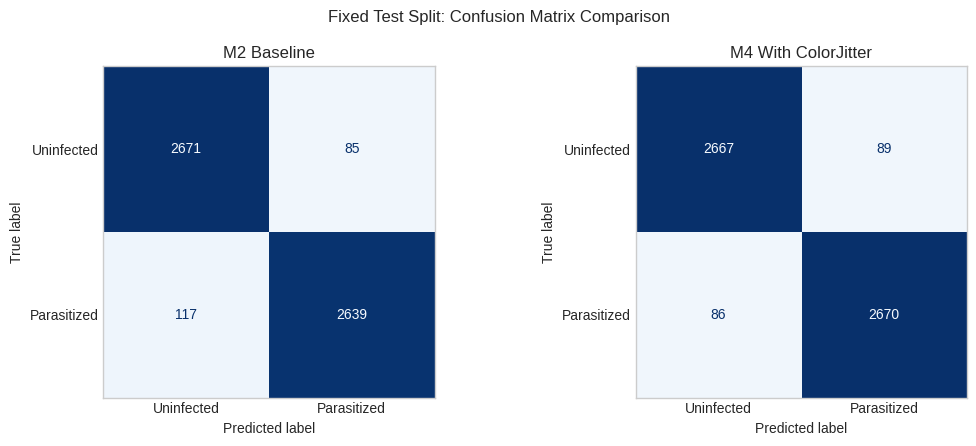

In [33]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.style.use("seaborn-v0_8-whitegrid")

modified_cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
class_names = ["Uninfected", "Parasitized"]
maximum_count = max(baseline_cm.max(), modified_cm.max())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, matrix, title in zip(
    axes,
    [baseline_cm, modified_cm],
    ["M2 Baseline", "M4 With ColorJitter"],
):
    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=class_names,
    )

    display_cm.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d",
        im_kw={"vmin": 0, "vmax": maximum_count},
    )

    ax.set_title(title)
    ax.grid(False)

fig.suptitle("Fixed Test Split: Confusion Matrix Comparison")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrix_comparison.png", dpi=200)
plt.show()

## 13. ROC Curve Comparison


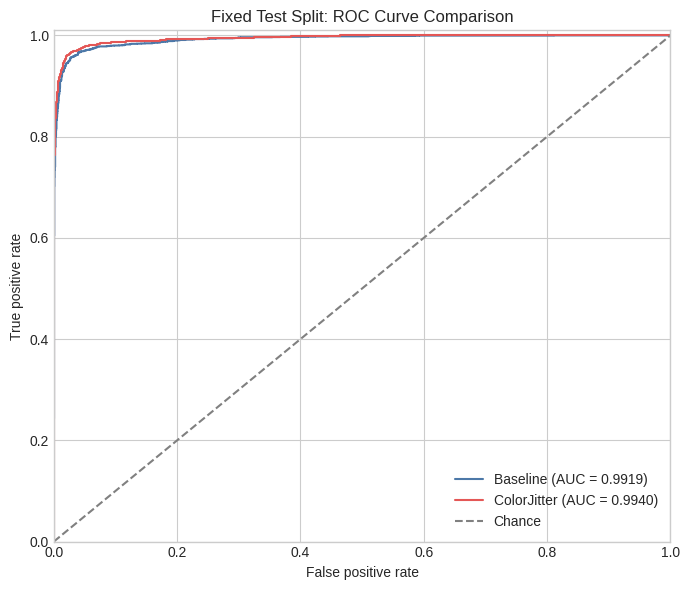

In [34]:
from sklearn.metrics import roc_curve

baseline_probability = baseline_aligned[
    "parasitized_probability"
].to_numpy()

baseline_fpr, baseline_tpr, _ = roc_curve(
    y_true, baseline_probability
)
modified_fpr, modified_tpr, _ = roc_curve(
    y_true, y_probability
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    baseline_fpr,
    baseline_tpr,
    color="#4C78A8",
    label=f"Baseline (AUC = {baseline_metrics['roc_auc']:.4f})",
)
ax.plot(
    modified_fpr,
    modified_tpr,
    color="#E45756",
    label=f"ColorJitter (AUC = {test_metrics['roc_auc']:.4f})",
)
ax.plot(
    [0, 1],
    [0, 1],
    color="gray",
    linestyle="--",
    label="Chance",
)

ax.set_title("Fixed Test Split: ROC Curve Comparison")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "roc_curve_comparison.png", dpi=200)
plt.show()

## 14. Precision–Recall Curve Comparison


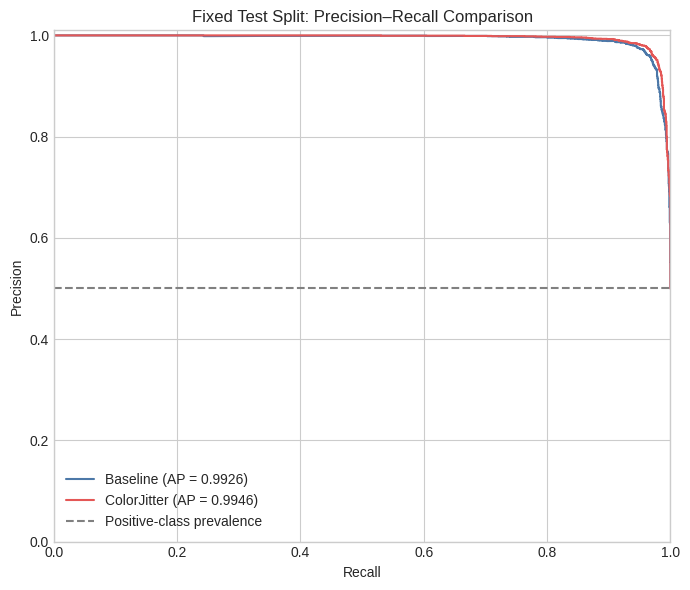

In [35]:
from sklearn.metrics import precision_recall_curve

baseline_precision, baseline_recall, _ = precision_recall_curve(
    y_true, baseline_probability
)
modified_precision, modified_recall, _ = precision_recall_curve(
    y_true, y_probability
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    baseline_recall,
    baseline_precision,
    color="#4C78A8",
    label=f"Baseline (AP = {baseline_metrics['average_precision']:.4f})",
)
ax.plot(
    modified_recall,
    modified_precision,
    color="#E45756",
    label=f"ColorJitter (AP = {test_metrics['average_precision']:.4f})",
)
ax.axhline(
    y_true.mean(),
    color="gray",
    linestyle="--",
    label="Positive-class prevalence",
)

ax.set_title("Fixed Test Split: Precision–Recall Comparison")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.legend(loc="lower left")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "precision_recall_comparison.png", dpi=200)
plt.show()

## 15. Classification Metric Comparison


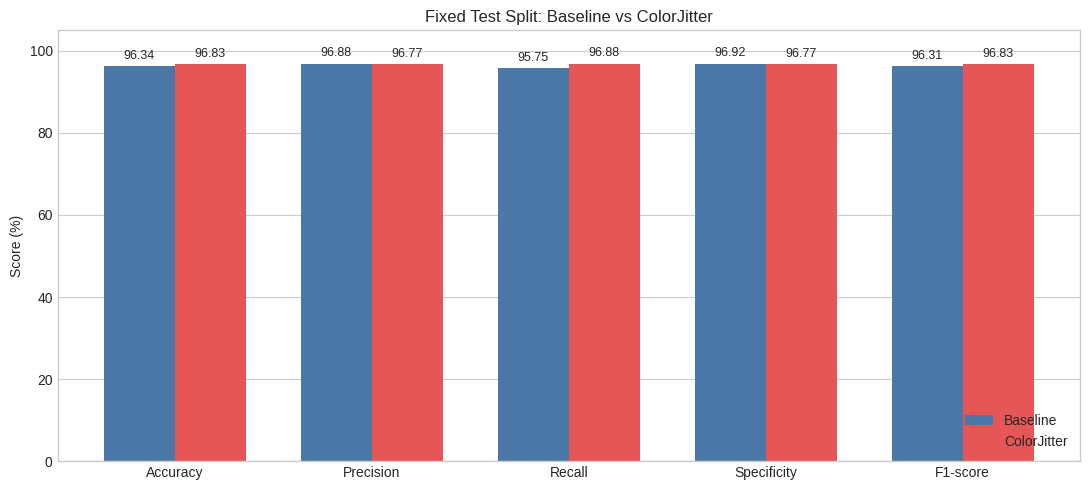

In [36]:
plot_metrics = comparison_df.iloc[:5].copy()
positions = np.arange(len(plot_metrics))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(11, 5))

baseline_bars = ax.bar(
    positions - bar_width / 2,
    plot_metrics["baseline"],
    bar_width,
    label="Baseline",
    color="#4C78A8",
)
modified_bars = ax.bar(
    positions + bar_width / 2,
    plot_metrics["colorjitter"],
    bar_width,
    label="ColorJitter",
    color="#E45756",
)

ax.bar_label(baseline_bars, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(modified_bars, fmt="%.2f", padding=3, fontsize=9)

ax.set_xticks(
    positions,
    plot_metrics["metric"].str.replace(" (%)", "", regex=False),
)
ax.set_ylim(0, 105)
ax.set_ylabel("Score (%)")
ax.set_title("Fixed Test Split: Baseline vs ColorJitter")
ax.legend(loc="lower right")
ax.set_axisbelow(True)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "metric_comparison.png", dpi=200)
plt.show()

## 16. Per-Class Classification Report


In [37]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Uninfected", "Parasitized"],
    output_dict=True,
    zero_division=0,
)

classification_report_df = pd.DataFrame(report).transpose()

classification_report_df.to_csv(
    EVALUATION_DIR / "test_classification_report.csv",
    index_label="class_or_average",
)

print("ColorJitter model: test classification report")
display(classification_report_df.round(6))
print("Classification report saved.")

ColorJitter model: test classification report


,precision,recall,f1-score,support
Uninfected,0.968761,0.967707,0.968234,2756.000000
Parasitized,0.967742,0.968795,0.968268,2756.000000
accuracy,0.968251,0.968251,0.968251,0.968251
macro avg,0.968252,0.968251,0.968251,5512.000000
weighted avg,0.968252,0.968251,0.968251,5512.000000


Classification report saved.


## 17. Reproducible Prediction Examples

Three examples per outcome are sampled with seed 42. These images are descriptive; they do not establish why the model made an error.


In [38]:
example_groups = [
    ("True negative", 0, 0),
    ("True positive", 1, 1),
    ("False positive", 0, 1),
    ("False negative", 1, 0),
]

selected_examples = []

for category, true_label, predicted_label in example_groups:
    candidates = predictions_df[
        (predictions_df["label"] == true_label)
        & (predictions_df["predicted_label"] == predicted_label)
    ]

    examples = candidates.sample(n=3, random_state=SEED).copy()
    examples["category"] = category
    selected_examples.append(examples)

examples_df = pd.concat(selected_examples, ignore_index=True)

examples_df.to_csv(
    EVALUATION_DIR / "prediction_examples.csv",
    index=False,
)

print("Three randomly sampled examples per category:")
display(examples_df[[
    "category",
    "relative_path",
    "class_name",
    "predicted_class",
    "parasitized_probability",
]])

Three randomly sampled examples per category:


,category,relative_path,class_name,predicted_class,parasitized_probability
0,True negative,Uninfected/C123P84ThinF_IMG_20151002_151851_ce...,Uninfected,Uninfected,0.000326
1,True negative,Uninfected/C38P3thinF_original_IMG_20150621_11...,Uninfected,Uninfected,0.000697
2,True negative,Uninfected/C227ThinF_IMG_20151112_135509_cell_...,Uninfected,Uninfected,0.000317
3,True positive,Parasitized/C182P143NThinF_IMG_20151201_172524...,Parasitized,Parasitized,0.956692
4,True positive,Parasitized/C116P77ThinF_IMG_20150930_171809_c...,Parasitized,Parasitized,0.997189
5,True positive,Parasitized/C51AP12thinF_IMG_20150724_153313_c...,Parasitized,Parasitized,0.977080
6,False positive,Uninfected/C214ThinF_IMG_20151106_115440_cell_...,Uninfected,Parasitized,0.594445
7,False positive,Uninfected/C39P4thinF_original_IMG_20150622_10...,Uninfected,Parasitized,0.746254
8,False positive,Uninfected/C168P129ThinF_IMG_20151118_154651_c...,Uninfected,Parasitized,0.514037
9,False negative,Parasitized/C84P45ThinF_IMG_20150818_104849_ce...,Parasitized,Uninfected,0.001720


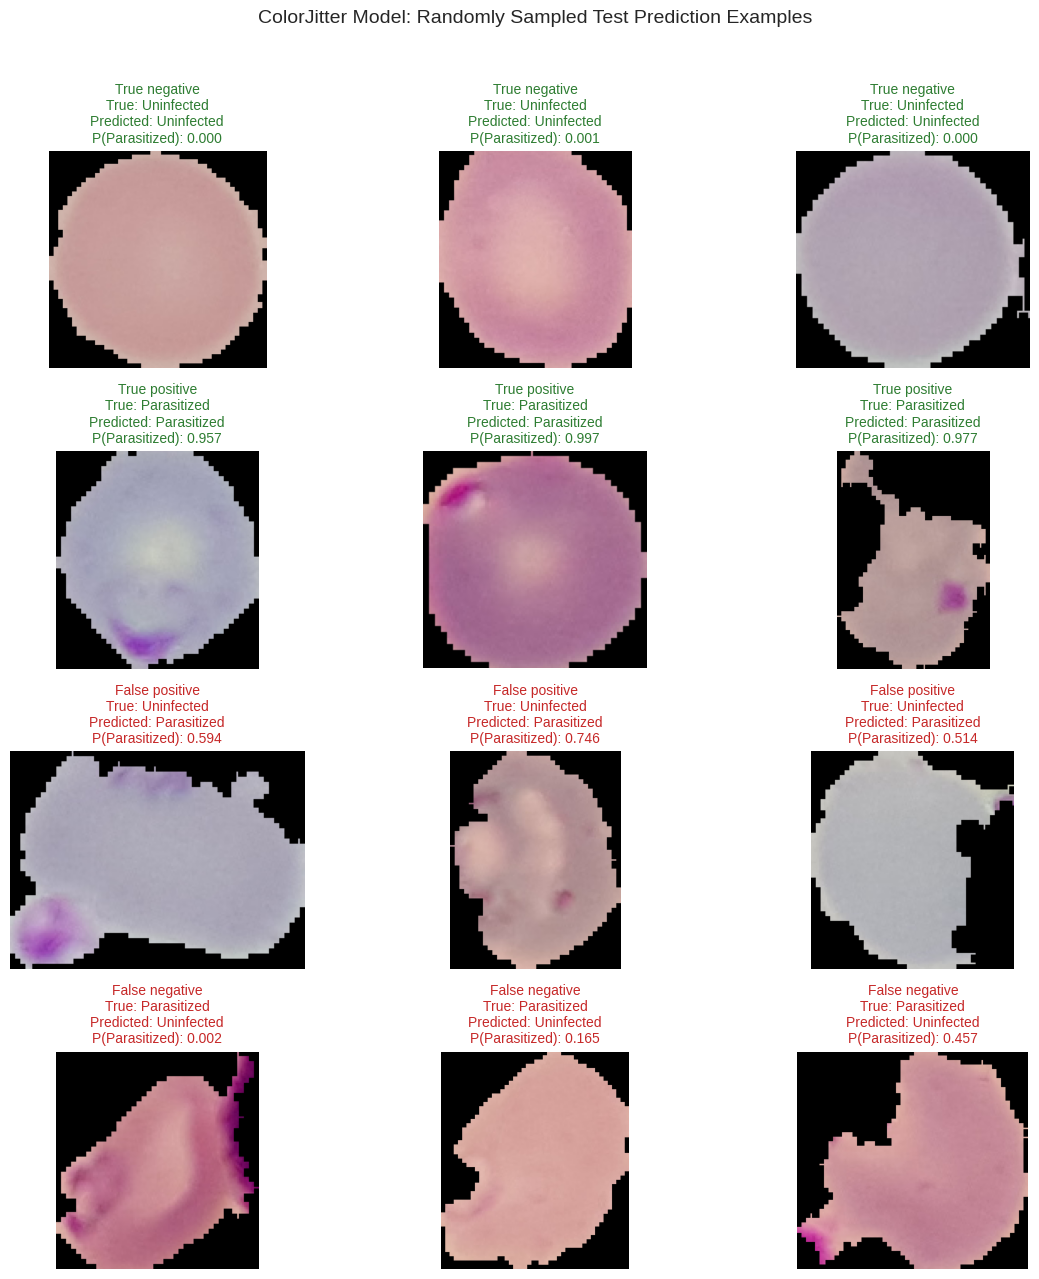

In [39]:
fig, axes = plt.subplots(4, 3, figsize=(12, 13))

for ax, (_, row) in zip(axes.flat, examples_df.iterrows()):
    with Image.open(IMAGE_ROOT / row["relative_path"]) as image:
        ax.imshow(image.convert("RGB"))

    title_color = "#2E7D32" if row["correct"] else "#C62828"

    ax.set_title(
        f"{row['category']}\n"
        f"True: {row['class_name']}\n"
        f"Predicted: {row['predicted_class']}\n"
        f"P(Parasitized): {row['parasitized_probability']:.3f}",
        fontsize=10,
        color=title_color,
    )
    ax.axis("off")

fig.suptitle(
    "ColorJitter Model: Randomly Sampled Test Prediction Examples",
    fontsize=14,
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(FIGURES_DIR / "prediction_examples.png", dpi=200)
plt.show()

## 18. Actual Results Against M3 Predictions

Prediction ranges are distinct from the success criteria. Recall exceeded its predicted range while meeting the minimum improvement criterion.


In [40]:
prediction_specs = [
    ("Accuracy (%)", 96.54, 97.14, test_metrics["accuracy"] * 100),
    ("Recall (%)", 96.05, 96.75, test_metrics["recall"] * 100),
    ("F1-score (%)", 96.51, 97.11, test_metrics["f1_score"] * 100),
    ("ROC-AUC", 0.9919, None, test_metrics["roc_auc"]),
]

prediction_rows = []

for metric, lower, upper, actual in prediction_specs:
    if actual < lower:
        outcome = "Below prediction"
    elif upper is not None and actual > upper:
        outcome = "Above predicted range"
    else:
        outcome = "Within prediction"

    prediction_rows.append({
        "metric": metric,
        "predicted_minimum": lower,
        "predicted_maximum": upper,
        "actual": actual,
        "outcome": outcome,
    })

prediction_comparison_df = pd.DataFrame(prediction_rows)

prediction_comparison_df.to_csv(
    EVALUATION_DIR / "m3_prediction_comparison.csv",
    index=False,
)

display(prediction_comparison_df.round(6))
print("M3 prediction comparison saved.")

,metric,predicted_minimum,predicted_maximum,actual,outcome
0,Accuracy (%),96.5400,97.14,96.825109,Within prediction
1,Recall (%),96.0500,96.75,96.879536,Above predicted range
2,F1-score (%),96.5100,97.11,96.826836,Within prediction
3,ROC-AUC,0.9919,NaN,0.994025,Within prediction


M3 prediction comparison saved.


## 19. Paired Prediction Outcomes


In [41]:
baseline_correct = (
    baseline_aligned["predicted_label"].to_numpy() == y_true
)
modified_correct = y_pred == y_true

paired_outcomes = {
    "Both correct": int((baseline_correct & modified_correct).sum()),
    "Baseline wrong, ColorJitter correct": int(
        (~baseline_correct & modified_correct).sum()
    ),
    "Baseline correct, ColorJitter wrong": int(
        (baseline_correct & ~modified_correct).sum()
    ),
    "Both wrong": int((~baseline_correct & ~modified_correct).sum()),
}

assert sum(paired_outcomes.values()) == len(y_true)
assert (
    paired_outcomes["Baseline wrong, ColorJitter correct"]
    - paired_outcomes["Baseline correct, ColorJitter wrong"]
) == (
    baseline_metrics["incorrect_predictions"]
    - int((y_pred != y_true).sum())
)

paired_outcomes_df = pd.DataFrame(
    paired_outcomes.items(),
    columns=["outcome", "images"],
)

paired_outcomes_df.to_csv(
    EVALUATION_DIR / "paired_prediction_outcomes.csv",
    index=False,
)

display(paired_outcomes_df)
print("Paired prediction outcomes saved.")

,outcome,images
0,Both correct,5258
1,"Baseline wrong, ColorJitter correct",79
2,"Baseline correct, ColorJitter wrong",52
3,Both wrong,123


Paired prediction outcomes saved.


## 20. Evaluation Configuration and Environment


In [42]:
evaluation_config = {
    "model": "DANet-S with ColorJitter",
    "checkpoint_file": MODEL_PATH.name,
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "checkpoint_sha256": model_sha256,
    "split_manifest_sha256": manifest_sha256,
    "test_samples": len(test_records),
    "class_mapping": data_config["class_mapping"],
    "input_size": list(image_size),
    "batch_size": batch_size,
    "data_loader_workers": 0,
    "shuffle": False,
    "test_transform": ["Resize((224, 224))", "ToTensor()"],
    "precision": "float32",
    "mixed_precision": False,
    "prediction_rule": "argmax of two class log probabilities",
    "positive_class": "Parasitized",
    "positive_label": 1,
    "loss": "NLLLoss with sum reduction, divided by test samples",
    "device": str(device),
    "random_seed": SEED,
    "baseline_checkpoint_epoch": baseline_config["checkpoint_epoch"],
    "baseline_checkpoint_sha256": baseline_config["checkpoint_sha256"],
    "baseline_metrics_sha256": file_hash(BASELINE_METRICS_PATH),
    "baseline_predictions_sha256": file_hash(BASELINE_PREDICTIONS_PATH),
    "baseline_config_sha256": file_hash(BASELINE_CONFIG_PATH),
    "comparison_limitation": training_config["comparison_limitation"],
    "patient_overlap_note": data_config["patient_overlap_note"],
}

with open(EVALUATION_DIR / "evaluation_config.json", "w") as file:
    json.dump(evaluation_config, file, indent=2)

print(json.dumps(evaluation_config, indent=2))

{
  "model": "DANet-S with ColorJitter",
  "checkpoint_file": "danet_s_colorjitter_best.pth",
  "checkpoint_epoch": 62,
  "checkpoint_sha256": "ee7bc1fd413439343fda5a3b8dddad5f0a6bdbe98981488da2c1eb56775f30b3",
  "split_manifest_sha256": "aea08bdec4626ae188204039369aafe14b3a9ac9ce0782077458d9428f26091d",
  "test_samples": 5512,
  "class_mapping": {
    "Uninfected": 0,
    "Parasitized": 1
  },
  "input_size": [
    224,
    224
  ],
  "batch_size": 64,
  "data_loader_workers": 0,
  "shuffle": false,
  "test_transform": [
    "Resize((224, 224))",
    "ToTensor()"
  ],
  "precision": "float32",
  "mixed_precision": false,
  "prediction_rule": "argmax of two class log probabilities",
  "positive_class": "Parasitized",
  "positive_label": 1,
  "loss": "NLLLoss with sum reduction, divided by test samples",
  "device": "cuda",
  "random_seed": 42,
  "baseline_checkpoint_epoch": 67,
  "baseline_checkpoint_sha256": "d08ff52e3c0682fadf0b23b631b916305405e1c9693e2f581dec26b5ba4f0aa1",
  "baseli

In [43]:
import platform

import PIL
import sklearn
import torchvision

evaluation_environment = {
    "python": platform.python_version(),
    "pytorch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "pillow": PIL.__version__,
    "scikit_learn": sklearn.__version__,
    "matplotlib": plt.matplotlib.__version__,
    "cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version(),
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
}

with open(EVALUATION_DIR / "evaluation_environment.json", "w") as file:
    json.dump(evaluation_environment, file, indent=2)

print(json.dumps(evaluation_environment, indent=2))

{
  "python": "3.13.16",
  "pytorch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "pillow": "11.3.0",
  "scikit_learn": "1.6.1",
  "matplotlib": "3.10.0",
  "cuda": "13.0",
  "cudnn": 92700,
  "gpu": "Tesla T4"
}


## 21. Evaluation Summary and Limitations


In [44]:
summary = f"""# Milestone 4: Evaluation and Ablation

## Evaluation setup
- Model: DANet-S with mild training-only ColorJitter
- Selected checkpoint: epoch {checkpoint["epoch"]}, by validation loss
- Test images: {len(y_true):,}
- Split, image contents, and labels verified against the baseline
- Test preprocessing: resize and tensor conversion only
- Inference: float32, no mixed precision
- Positive class: Parasitized

## Modified-model test results
- Loss: {test_metrics["test_loss"]:.6f}
- Accuracy: {test_metrics["accuracy"] * 100:.2f}%
- Precision: {test_metrics["precision"] * 100:.2f}%
- Recall: {test_metrics["recall"] * 100:.2f}%
- Specificity: {test_metrics["specificity"] * 100:.2f}%
- F1-score: {test_metrics["f1_score"] * 100:.2f}%
- ROC-AUC: {test_metrics["roc_auc"]:.6f}
- Average precision: {test_metrics["average_precision"]:.6f}
- False negatives: {test_metrics["false_negatives"]}
- False positives: {test_metrics["false_positives"]}

## Comparison with the reproduced baseline
- Accuracy change: {accuracy_change * 100:+.4f} percentage points
- Recall change: {recall_change * 100:+.4f} percentage points
- F1-score change: {f1_change * 100:+.4f} percentage points
- False negatives decreased from 117 to 86.
- False positives increased from 85 to 89.
- Total errors decreased from 202 to 175.
- Precision and specificity decreased slightly.

## M3 predictions and success criteria
All three recorded success criteria were met on this fixed test split.
Accuracy and F1-score were within their predicted ranges.
Recall exceeded its predicted range, and ROC-AUC exceeded its predicted minimum.
The precision decrease was within the anticipated 0.5 percentage-point allowance.

## Paired outcomes
- Both models correct: {paired_outcomes["Both correct"]}
- Baseline wrong, modified model correct: {paired_outcomes["Baseline wrong, ColorJitter correct"]}
- Baseline correct, modified model wrong: {paired_outcomes["Baseline correct, ColorJitter wrong"]}
- Both models wrong: {paired_outcomes["Both wrong"]}

## Interpretation and limitations
The modified run achieved better accuracy, recall, F1-score, ROC-AUC, and
average precision on the same held-out images. These observations meet the
operational M3 success criteria.

{training_config["comparison_limitation"]}
This is therefore a baseline-versus-modified-run comparison with a training
schedule confound, rather than an isolated estimate of the ColorJitter effect.

The image-level split retains patient overlap across partitions.
Results cover one seed and one split; statistical significance and
generalization to other laboratories have not been established.
No explicit lighting/stain-shift robustness test was performed.
The displayed examples are descriptive and do not establish error causes.
These experimental results do not establish clinical validity.

## Checkpoint
- Filename: {MODEL_PATH.name}
- SHA-256: {model_sha256}
"""

SUMMARY_PATH = EVALUATION_DIR / "evaluation_ablation_summary.md"
SUMMARY_PATH.write_text(summary, encoding="utf-8")

print(summary)
print("Summary saved:", SUMMARY_PATH)

# Milestone 4: Evaluation and Ablation

## Evaluation setup
- Model: DANet-S with mild training-only ColorJitter
- Selected checkpoint: epoch 62, by validation loss
- Test images: 5,512
- Split, image contents, and labels verified against the baseline
- Test preprocessing: resize and tensor conversion only
- Inference: float32, no mixed precision
- Positive class: Parasitized

## Modified-model test results
- Loss: 0.093517
- Accuracy: 96.83%
- Precision: 96.77%
- Recall: 96.88%
- Specificity: 96.77%
- F1-score: 96.83%
- ROC-AUC: 0.994025
- Average precision: 0.994644
- False negatives: 86
- False positives: 89

## Comparison with the reproduced baseline
- Accuracy change: +0.4898 percentage points
- Recall change: +1.1248 percentage points
- F1-score change: +0.5130 percentage points
- False negatives decreased from 117 to 86.
- False positives increased from 85 to 89.
- Total errors decreased from 202 to 175.
- Precision and specificity decreased slightly.

## M3 predictions and succ

## 22. Artifact Checksums

The notebook exports to a flat Drive evaluation folder, with images under `figures/`. The repository stores the exported files under `model_evaluation/artifacts/`, retaining the manifest-relative figure paths.


In [45]:
artifact_names = [
    "test_predictions.csv",
    "test_metrics.json",
    "test_classification_report.csv",
    "baseline_colorjitter_comparison.csv",
    "hypothesis_assessment.json",
    "m3_prediction_comparison.csv",
    "paired_prediction_outcomes.csv",
    "prediction_examples.csv",
    "evaluation_config.json",
    "evaluation_environment.json",
    "evaluation_ablation_summary.md",
    "figures/confusion_matrix_comparison.png",
    "figures/roc_curve_comparison.png",
    "figures/precision_recall_comparison.png",
    "figures/metric_comparison.png",
    "figures/prediction_examples.png",
]

artifacts = []

for name in artifact_names:
    path = EVALUATION_DIR / name
    assert path.is_file(), f"Missing artifact: {path}"

    artifacts.append({
        "filename": name,
        "size_bytes": path.stat().st_size,
        "sha256": file_hash(path),
    })

ARTIFACT_MANIFEST_PATH = (
    EVALUATION_DIR / "evaluation_artifact_manifest.json"
)

with open(ARTIFACT_MANIFEST_PATH, "w") as file:
    json.dump(artifacts, file, indent=2)

display(pd.DataFrame(artifacts))
print("All 16 evaluation artifacts recorded.")
print("Artifact manifest saved:", ARTIFACT_MANIFEST_PATH)

,filename,size_bytes,sha256
0,test_predictions.csv,1441478,cede5aac605fc8b4c0efdd8cde1ad3c703ba55c2384820...
1,test_metrics.json,406,f66212214e6213107d2f8f916795dd354cc3d2c9ba994b...
2,test_classification_report.csv,437,21a4a9bfc55adb249ae83df5037df8e5e574b25a64e38e...
3,baseline_colorjitter_comparison.csv,654,6d686a12c92c0940cadceb67b00463ef304fbd2c6e8cb5...
4,hypothesis_assessment.json,665,376882ed3067dc66b74c1c00c412e64162c5206d7a88c2...
5,m3_prediction_comparison.csv,296,adb1b54eb7a8566d991b8a76700d75b7d19e2b0ca6ab0e...
6,paired_prediction_outcomes.csv,130,f46172862b8c5be2914c737997758c45e57d17cf380c2c...
7,prediction_examples.csv,3551,a5419bf7c78f104b79c2b9bfd11210132545c648abf7bd...
8,evaluation_config.json,1694,7520ccdb54fb366975028b146ea28feb5390f9061d66b2...
9,evaluation_environment.json,260,5d6151f61f962131872e60a1edadc43e6da9e2aa9a16fb...


All 16 evaluation artifacts recorded.
Artifact manifest saved: /content/drive/MyDrive/malaria_danet/milestone4/model_evaluation/evaluation_artifact_manifest.json
